<a href="https://colab.research.google.com/github/vishvampatel2006-creator/100-Days-Of-Code/blob/main/Day-22/day22_expense_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Raw rows: 10 -> Cleaned rows: 7
--- NumPy Summary Statistics (INR) ---
Valid records : 7
Total spend   : ₹12,350.00
Mean          : ₹1,764.29
Median        : ₹1,800.00
Std Deviation : ₹764.15
25th / 75th % : ₹1,200.00 / ₹2,500.00


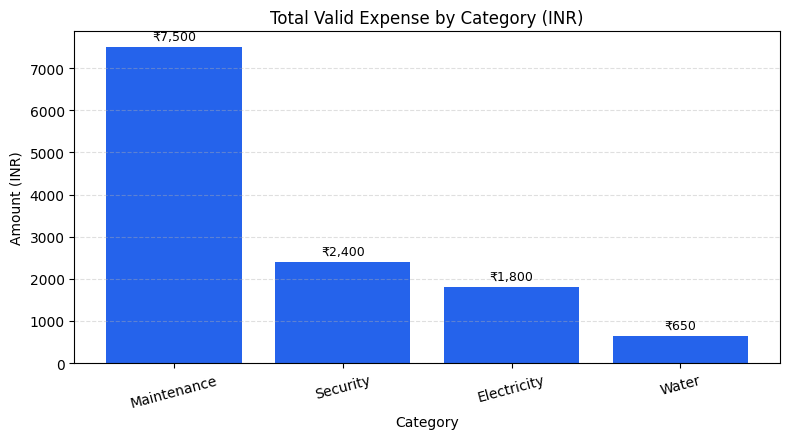

Saved chart to: /content/category_spend.png


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def create_sample_csv(csv_path: Path) -> None:
    sample_data = """date,flat_no,category,amount_inr
2026-11-01,A-101,Maintenance,2500
2026-11-02,A-102,Maintenance,2500
2026-11-03,B-201,Water,650
2026-11-04,B-202,Electricity,1800
2026-11-05,C-301,Maintenance,
2026-11-06,C-302,Water,-200
2026-11-07,invalid-date,Security,1200
2026-11-08,D-401,Security,1200
2026-11-09,D-402,Electricity,0
2026-11-10,A-103,Maintenance,2500
"""
    csv_path.write_text(sample_data.strip(), encoding="utf-8")


def clean_expenses(df: pd.DataFrame) -> pd.DataFrame:
    cleaned = df.copy()
    cleaned["category"] = cleaned["category"].astype(str).str.strip().str.title()
    cleaned["date"] = pd.to_datetime(cleaned["date"], errors="coerce")
    cleaned["amount_inr"] = pd.to_numeric(cleaned["amount_inr"], errors="coerce")

    cleaned = cleaned.dropna(subset=["date", "category", "amount_inr"])
    cleaned = cleaned[cleaned["amount_inr"] > 0].reset_index(drop=True)
    return cleaned


def print_summary_stats(amounts: np.ndarray) -> None:
    print("--- NumPy Summary Statistics (INR) ---")
    print(f"Valid records : {amounts.size}")
    print(f"Total spend   : ₹{np.sum(amounts):,.2f}")
    print(f"Mean          : ₹{np.mean(amounts):,.2f}")
    print(f"Median        : ₹{np.median(amounts):,.2f}")
    print(f"Std Deviation : ₹{np.std(amounts, ddof=1):,.2f}")
    print(f"25th / 75th % : ₹{np.percentile(amounts, 25):,.2f} / ₹{np.percentile(amounts, 75):,.2f}")


def save_and_show_chart(cleaned_df: pd.DataFrame, output_path: Path) -> None:
    category_totals = (
        cleaned_df.groupby("category", as_index=True)["amount_inr"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 4.5))
    bars = plt.bar(category_totals.index, category_totals.values, color="#2563eb")
    plt.title("Total Valid Expense by Category (INR)")
    plt.xlabel("Category")
    plt.ylabel("Amount (INR)")
    plt.xticks(rotation=15)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    for bar in bars:
        height = bar.get_height()
        plt.annotate(
            f"₹{height:,.0f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()


# Colab working directory use karein (__file__ ki jagah)
base_dir = Path.cwd()
csv_path = base_dir / "society_expenses.csv"
chart_path = base_dir / "category_spend.png"

if not csv_path.exists():
    create_sample_csv(csv_path)

raw_df = pd.read_csv(csv_path)
cleaned_df = clean_expenses(raw_df)

print(f"Raw rows: {len(raw_df)} -> Cleaned rows: {len(cleaned_df)}")
amounts_np = cleaned_df["amount_inr"].to_numpy(dtype=float)
print_summary_stats(amounts_np)

save_and_show_chart(cleaned_df, chart_path)
print(f"Saved chart to: {chart_path}")